# Feature engineering

Load the final rental dataset with all proximity features and explore
`weekly_rent`.

### Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

### Read the Rental Dataset in

In [2]:
FINAL_RENTALS_PATH = "External_Features_Processing/proximity_results/rentals_with_all_proximity_driving-car.parquet"

rentals = pd.read_parquet(FINAL_RENTALS_PATH)
print(rentals.shape)
rentals.head()

(12317, 105)


,lat,lon,listing_id,suburb,weekly_rent,date_listed,bedrooms,bathrooms,carspaces,property_type,...,park_local_duration_s,park_local_is_confirmed,nearest_school_primary_facility_id,school_primary_road_distance_m,school_primary_duration_s,school_primary_is_confirmed,nearest_school_secondary_facility_id,school_secondary_road_distance_m,school_secondary_duration_s,school_secondary_is_confirmed
0,-37.830982,144.87091,16782629,SOUTH KINGSVILLE,460.0,2025-08-13,2.0,1.0,2.0,Apartment / Unit / Flat,...,10.55,True,1527.0,1060.45,167.21,True,1654.0,2873.23,323.09,True
1,-37.826218,144.86755,17471867,SOUTH KINGSVILLE,400.0,2025-03-06,2.0,1.0,1.0,Apartment / Unit / Flat,...,61.54,True,1527.0,1401.63,188.94,True,1654.0,2995.49,323.28,True
2,-37.831226,144.86632,17721851,SOUTH KINGSVILLE,795.0,2025-08-19,3.0,2.0,3.0,Townhouse,...,51.79,True,1527.0,1482.51,196.82,True,1654.0,2490.46,275.72,True
3,-37.827423,144.86768,17725855,SOUTH KINGSVILLE,675.0,2025-08-21,3.0,1.0,2.0,Townhouse,...,32.73,True,1527.0,1118.25,149.96,True,1654.0,2950.51,315.92,True
4,-37.826270,144.86790,17745057,SOUTH KINGSVILLE,450.0,2025-09-03,2.0,1.0,0.0,Apartment / Unit / Flat,...,45.08,True,1527.0,1320.30,172.48,True,1654.0,3152.57,338.45,True


## Distribution of weekly rent

In [3]:
print(rentals["weekly_rent"].describe())
print(f"\nNulls: {rentals['weekly_rent'].isna().sum()}")

count    12317.000000
mean       630.932695
std        294.475063
min        205.000000
25%        490.000000
50%        565.000000
75%        690.000000
max      10000.000000
Name: weekly_rent, dtype: float64

Nulls: 0


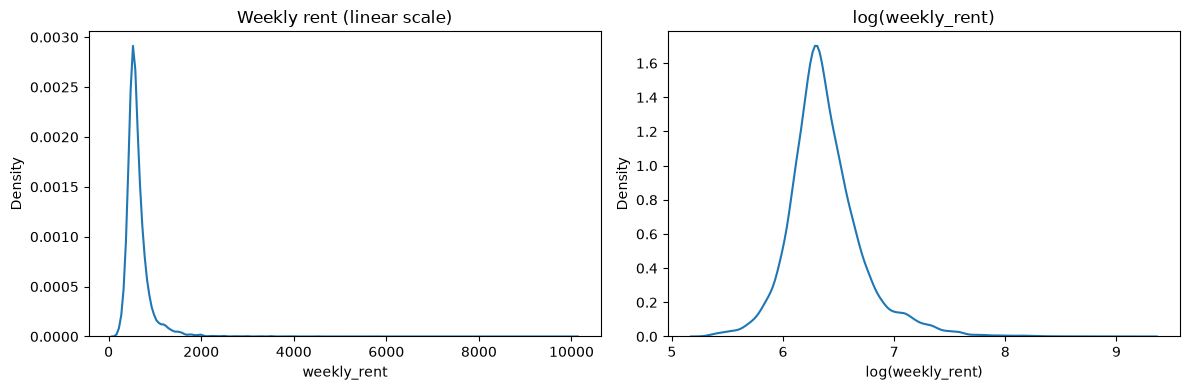

In [4]:
log_rent = np.log(rentals["weekly_rent"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(rentals["weekly_rent"], ax=axes[0])
axes[0].set_title("Weekly rent (linear scale)")

sns.kdeplot(log_rent, ax=axes[1])
axes[1].set_xlabel("log(weekly_rent)")
axes[1].set_title("log(weekly_rent)")

plt.tight_layout()
plt.show()